<a href="https://colab.research.google.com/github/4472-M/Assignments/blob/main/Ensemble_techniq.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Load dataset
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Bagging Classifier
bagging_clf = BaggingClassifier(base_estimator=DecisionTreeClassifier(), n_estimators=10, random_state=42)
bagging_clf.fit(X_train, y_train)

# Predictions
y_pred = bagging_clf.predict(X_test)

# Evaluate performance
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("Classification Report:\n", classification_report(y_test, y_pred))


TypeError: BaggingClassifier.__init__() got an unexpected keyword argument 'base_estimator'

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fix: Use 'estimator' instead of 'base_estimator'
bagging_clf = BaggingClassifier(estimator=DecisionTreeClassifier(),
                                n_estimators=10,
                                random_state=42)

# Train the model
bagging_clf.fit(X_train, y_train)

# Predictions
y_pred = bagging_clf.predict(X_test)

# Evaluate performance
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 1.0000
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [ ]:
from sklearn.model_selection import cross_val_score

# Perform 5-fold cross-validation
cv_scores = cross_val_score(bagging_clf, X, y, cv=5, scoring='accuracy')

print(f"Cross-Validation Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")


Cross-Validation Accuracy: 0.9533 ± 0.0340


In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Load dataset
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Corrected Code: Use 'estimator' instead of 'base_estimator'
bagging_clf = BaggingClassifier(estimator=DecisionTreeClassifier(),
                                n_estimators=10,
                                oob_score=True,
                                random_state=42)

# Train the model
bagging_clf.fit(X_train, y_train)

# Print OOB Score
print(f"OOB Score: {bagging_clf.oob_score_:.4f}")


OOB Score: 0.9167


In [ ]:
single_tree = DecisionTreeClassifier()
single_tree.fit(X_train, y_train)
y_tree_pred = single_tree.predict(X_test)

print(f"Single Decision Tree Accuracy: {accuracy_score(y_test, y_tree_pred):.4f}")
print(f"Bagging Classifier Accuracy: {accuracy_score(y_test, y_pred):.4f}")


Single Decision Tree Accuracy: 1.0000
Bagging Classifier Accuracy: 1.0000


In [ ]:
import numpy as np
from sklearn.utils import resample

# Original dataset
data = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

# Create a bootstrap sample
bootstrap_sample = resample(data, replace=True, n_samples=len(data), random_state=42)

print("Original Data:", data)
print("Bootstrap Sample:", bootstrap_sample)


Original Data: [ 1  2  3  4  5  6  7  8  9 10]
Bootstrap Sample: [ 7  4  8  5  7 10  3  7  8  5]


In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score

# Load dataset
iris = load_iris()
X, y = iris.data, iris.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# ✅ Corrected: Use `estimator` instead of `base_estimator`
bagging_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(),  # Decision Tree as base model
    n_estimators=10,  # Number of trees
    random_state=42
)

# Train the model
bagging_clf.fit(X_train, y_train)

# Make predictions
y_pred = bagging_clf.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Bagging Classifier Accuracy: {accuracy:.4f}")



Bagging Classifier Accuracy: 1.0000


In [ ]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error

# Load dataset (California Housing dataset)
data = fetch_california_housing()
X, y = data.data, data.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize Bagging Regressor with Decision Trees
bagging_reg = BaggingRegressor(
    estimator=DecisionTreeRegressor(),  # Decision Tree as base model
    n_estimators=10,  # Number of trees
    random_state=42
)

# Train the model
bagging_reg.fit(X_train, y_train)

# Make predictions
y_pred = bagging_reg.predict(X_test)

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)
print(f"Bagging Regressor Mean Squared Error (MSE): {mse:.4f}")


Bagging Regressor Mean Squared Error (MSE): 0.2862


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target
feature_names = data.feature_names

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
rf_clf.fit(X_train, y_train)

# Get feature importance scores
feature_importances = rf_clf.feature_importances_

# Convert to DataFrame for better readability
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Print feature importance scores
print(importance_df)


                    Feature  Importance
7       mean concave points    0.141934
27     worst concave points    0.127136
23               worst area    0.118217
6            mean concavity    0.080557
20             worst radius    0.077975
22          worst perimeter    0.074292
2            mean perimeter    0.060092
3                 mean area    0.053810
26          worst concavity    0.041080
0               mean radius    0.032312
13               area error    0.029538
21            worst texture    0.018786
25        worst compactness    0.017539
10             radius error    0.016435
28           worst symmetry    0.012929
12          perimeter error    0.011770
24         worst smoothness    0.011769
1              mean texture    0.011064
5          mean compactness    0.009216
19  fractal dimension error    0.007135
29  worst fractal dimension    0.006924
4           mean smoothness    0.006223
14         smoothness error    0.005881
16          concavity error    0.005816


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error

# Load dataset
data = fetch_california_housing()
X, y = data.data, data.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize models
tree_regressor = DecisionTreeRegressor(random_state=42)
rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42)

# Train models
tree_regressor.fit(X_train, y_train)
rf_regressor.fit(X_train, y_train)

# Make predictions
tree_preds = tree_regressor.predict(X_test)
rf_preds = rf_regressor.predict(X_test)

# Calculate Mean Squared Error (MSE)
tree_mse = mean_squared_error(y_test, tree_preds)
rf_mse = mean_squared_error(y_test, rf_preds)

# Print results
print(f"Decision Tree Regressor MSE: {tree_mse:.4f}")
print(f"Random Forest Regressor MSE: {rf_mse:.4f}")


Decision Tree Regressor MSE: 0.5280
Random Forest Regressor MSE: 0.2565


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize Random Forest Classifier with OOB scoring enabled
rf_clf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42, bootstrap=True)

# Train the model
rf_clf.fit(X_train, y_train)

# Print OOB Score
print(f"Out-of-Bag (OOB) Score: {rf_clf.oob_score_:.4f}")


Out-of-Bag (OOB) Score: 0.9548


In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize Bagging Classifier with SVM as the base estimator
bagging_clf = BaggingClassifier(
    estimator=SVC(),  # SVM as base model
    n_estimators=10,  # Number of base models
    random_state=42
)

# Train the model
bagging_clf.fit(X_train, y_train)

# Make predictions
y_pred = bagging_clf.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Bagging Classifier (SVM) Accuracy: {accuracy:.4f}")


Bagging Classifier (SVM) Accuracy: 0.9415


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Define different numbers of trees to test
n_trees = [1, 5, 10, 50, 100, 200]

# Dictionary to store accuracy results
accuracy_results = {}

# Train and evaluate models with different tree counts
for n in n_trees:
    rf_clf = RandomForestClassifier(n_estimators=n, random_state=42)
    rf_clf.fit(X_train, y_train)
    y_pred = rf_clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_results[n] = accuracy
    print(f"Random Forest with {n} trees - Accuracy: {accuracy:.4f}")

# Print summary
print("\nSummary of Accuracy Results:")
for n, acc in accuracy_results.items():
    print(f"{n} trees: {acc:.4f}")


Random Forest with 1 trees - Accuracy: 0.9474
Random Forest with 5 trees - Accuracy: 0.9649
Random Forest with 10 trees - Accuracy: 0.9649
Random Forest with 50 trees - Accuracy: 0.9708
Random Forest with 100 trees - Accuracy: 0.9708
Random Forest with 200 trees - Accuracy: 0.9708

Summary of Accuracy Results:
1 trees: 0.9474
5 trees: 0.9649
10 trees: 0.9649
50 trees: 0.9708
100 trees: 0.9708
200 trees: 0.9708


In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardize features (fixes convergence issues)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Initialize Bagging Classifier with Logistic Regression as base estimator
bagging_clf = BaggingClassifier(
    estimator=LogisticRegression(max_iter=5000, solver='lbfgs'),  # Increased iterations
    n_estimators=10,  # Number of base models
    random_state=42
)

# Train the model
bagging_clf.fit(X_train, y_train)

# Make probability predictions
y_prob = bagging_clf.predict_proba(X_test)[:, 1]  # Get probabilities for the positive class

# Calculate AUC score
auc_score = roc_auc_score(y_test, y_prob)
print(f"Bagging Classifier (Logistic Regression) AUC Score: {auc_score:.4f}")



Bagging Classifier (Logistic Regression) AUC Score: 0.9974


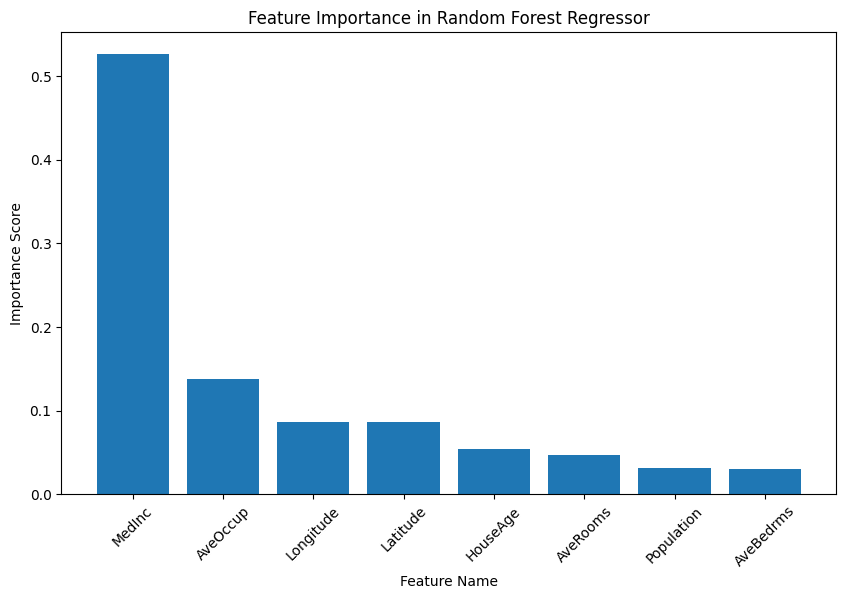

MedInc: 0.5260
AveOccup: 0.1382
Longitude: 0.0861
Latitude: 0.0861
HouseAge: 0.0547
AveRooms: 0.0472
Population: 0.0317
AveBedrms: 0.0300


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing

# Load dataset
data = fetch_california_housing()
X, y = data.data, data.target
feature_names = data.feature_names

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train Random Forest Regressor
rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42)
rf_regressor.fit(X_train, y_train)

# Get feature importance scores
feature_importances = rf_regressor.feature_importances_

# Sort features by importance
sorted_idx = np.argsort(feature_importances)[::-1]

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.bar(range(len(feature_importances)), feature_importances[sorted_idx], align="center")
plt.xticks(range(len(feature_importances)), np.array(feature_names)[sorted_idx], rotation=45)
plt.xlabel("Feature Name")
plt.ylabel("Importance Score")
plt.title("Feature Importance in Random Forest Regressor")
plt.show()

# Print feature importance scores
for i in sorted_idx:
    print(f"{feature_names[i]}: {feature_importances[i]:.4f}")


In [ ]:
import numpy as np
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error

# Load dataset
data = fetch_california_housing()
X, y = data.data, data.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=50)

# Train Bagging Regressor with Decision Trees
bagging_regressor = BaggingRegressor(
    estimator=DecisionTreeRegressor(),  # Updated parameter name
    n_estimators=50,
    random_state=42
)
bagging_regressor.fit(X_train, y_train)
y_pred_bagging = bagging_regressor.predict(X_test)

# Train Random Forest Regressor
rf_regressor = RandomForestRegressor(n_estimators=50, random_state=42)
rf_regressor.fit(X_train, y_train)
y_pred_rf = rf_regressor.predict(X_test)

# Compute Mean Squared Error (MSE)
mse_bagging = mean_squared_error(y_test, y_pred_bagging)
mse_rf = mean_squared_error(y_test, y_pred_rf)

# Print the results
print(f"Bagging Regressor MSE: {mse_bagging:.4f}")
print(f"Random Forest Regressor MSE: {mse_rf:.4f}")

# Compare performance
if mse_rf < mse_bagging:
    print("✅ Random Forest performed better!")
else:
    print("✅ Bagging performed better!")


Bagging Regressor MSE: 0.2638
Random Forest Regressor MSE: 0.2638
✅ Bagging performed better!


In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define RandomForestClassifier
rf = RandomForestClassifier(random_state=42)

# Define hyperparameters for tuning
param_grid = {
    'n_estimators': [50, 100, 150],  # Number of trees in the forest
    'max_depth': [None, 10, 20],     # Maximum depth of the tree
    'min_samples_split': [2, 5, 10], # Min samples to split an internal node
    'min_samples_leaf': [1, 2, 4]    # Min samples at a leaf node
}

# Use GridSearchCV for hyperparameter tuning
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(X_train, y_train)

# Get the best model
best_rf = grid_search.best_estimator_

# Predict on the test set
y_pred = best_rf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Test Accuracy: {accuracy:.4f}")


Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 150}
Test Accuracy: 1.0000


n_estimators = 5 | MSE: 0.3060 | R² Score: 0.7665
n_estimators = 10 | MSE: 0.2824 | R² Score: 0.7845
n_estimators = 20 | MSE: 0.2643 | R² Score: 0.7983
n_estimators = 50 | MSE: 0.2573 | R² Score: 0.8036
n_estimators = 100 | MSE: 0.2559 | R² Score: 0.8047


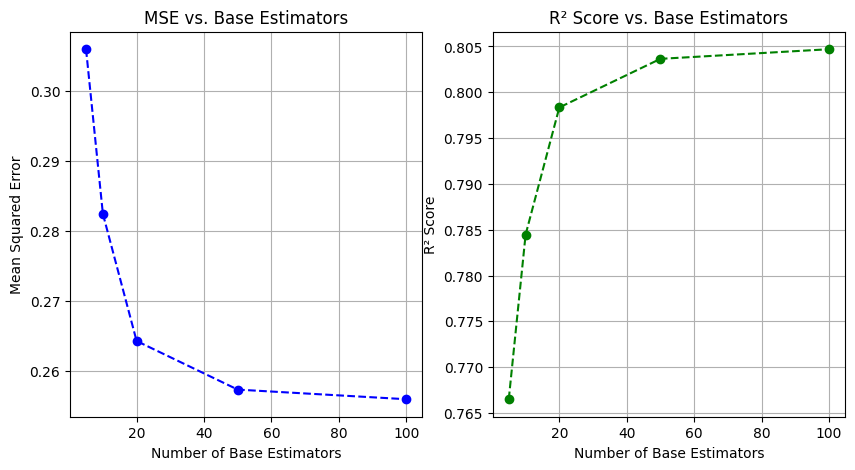

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
housing = fetch_california_housing()
X = housing.data
y = housing.target

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define different numbers of base estimators to compare
n_estimators_list = [5, 10, 20, 50, 100]

# Store performance results
mse_scores = []
r2_scores = []

# Train and evaluate models
for n in n_estimators_list:
    bagging_reg = BaggingRegressor(estimator=DecisionTreeRegressor(),
                                   n_estimators=n, random_state=42, n_jobs=-1)
    bagging_reg.fit(X_train, y_train)

    # Predict on test set
    y_pred = bagging_reg.predict(X_test)

    # Evaluate performance
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    mse_scores.append(mse)
    r2_scores.append(r2)

    print(f"n_estimators = {n} | MSE: {mse:.4f} | R² Score: {r2:.4f}")

# Plot performance comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(n_estimators_list, mse_scores, marker='o', linestyle='--', color='b', label='MSE')
plt.xlabel('Number of Base Estimators')
plt.ylabel('Mean Squared Error')
plt.title('MSE vs. Base Estimators')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(n_estimators_list, r2_scores, marker='o', linestyle='--', color='g', label='R² Score')
plt.xlabel('Number of Base Estimators')
plt.ylabel('R² Score')
plt.title('R² Score vs. Base Estimators')
plt.grid()

plt.show()



Total Misclassified Samples: 3
Sample 1: True Label = virginica, Predicted = versicolor
Sample 2: True Label = virginica, Predicted = versicolor
Sample 3: True Label = versicolor, Predicted = virginica


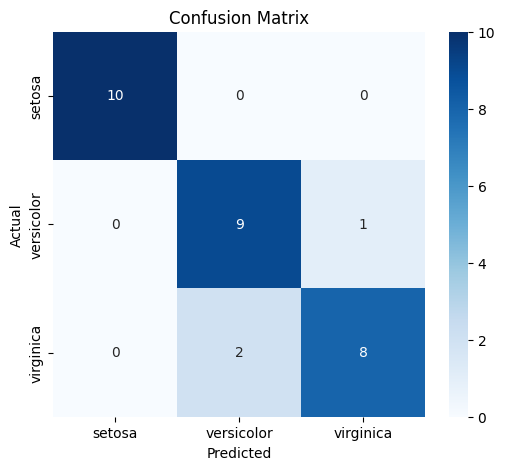


Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names  # Class labels

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Make predictions
y_pred = rf.predict(X_test)

# Identify misclassified samples
misclassified_indices = np.where(y_pred != y_test)[0]
misclassified_samples = X_test[misclassified_indices]
true_labels = y_test[misclassified_indices]
predicted_labels = y_pred[misclassified_indices]

# Display misclassified samples
print(f"Total Misclassified Samples: {len(misclassified_indices)}")
for i, index in enumerate(misclassified_indices):
    print(f"Sample {i + 1}: True Label = {target_names[true_labels[i]]}, Predicted = {target_names[predicted_labels[i]]}")

# Generate Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Print Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=target_names))


Decision Tree Accuracy: 0.9333
Bagging Classifier Accuracy: 0.9667


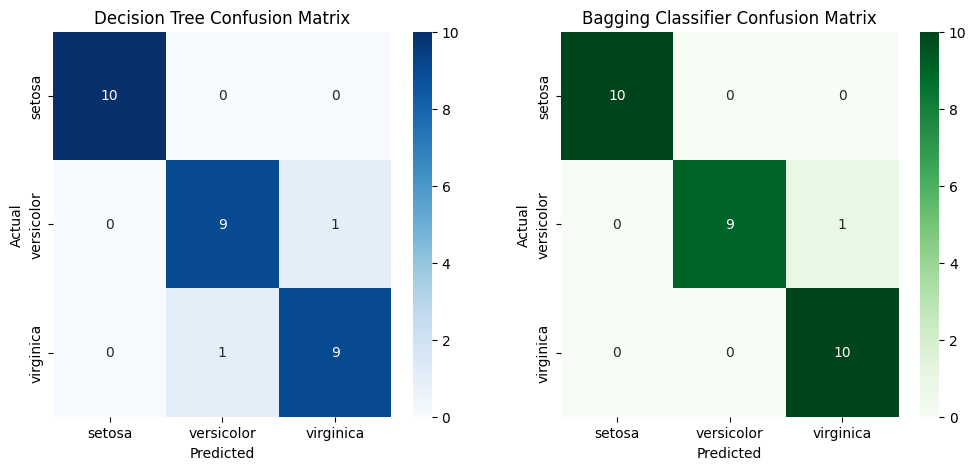


Decision Tree Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Bagging Classifier Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names  # Class labels

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train a single Decision Tree Classifier
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
dt_accuracy = accuracy_score(y_test, y_pred_dt)

# Train a Bagging Classifier with Decision Trees
bagging_clf = BaggingClassifier(estimator=DecisionTreeClassifier(),
                                n_estimators=50, random_state=42, n_jobs=-1)
bagging_clf.fit(X_train, y_train)
y_pred_bagging = bagging_clf.predict(X_test)
bagging_accuracy = accuracy_score(y_test, y_pred_bagging)

# Print Accuracy Scores
print(f"Decision Tree Accuracy: {dt_accuracy:.4f}")
print(f"Bagging Classifier Accuracy: {bagging_accuracy:.4f}")

# Generate Confusion Matrices
conf_matrix_dt = confusion_matrix(y_test, y_pred_dt)
conf_matrix_bagging = confusion_matrix(y_test, y_pred_bagging)

# Plot Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(conf_matrix_dt, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names, ax=axes[0])
axes[0].set_title("Decision Tree Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(conf_matrix_bagging, annot=True, fmt='d', cmap='Greens', xticklabels=target_names, yticklabels=target_names, ax=axes[1])
axes[1].set_title("Bagging Classifier Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.show()

# Print Classification Reports
print("\nDecision Tree Classification Report:\n", classification_report(y_test, y_pred_dt, target_names=target_names))
print("\nBagging Classifier Classification Report:\n", classification_report(y_test, y_pred_bagging, target_names=target_names))


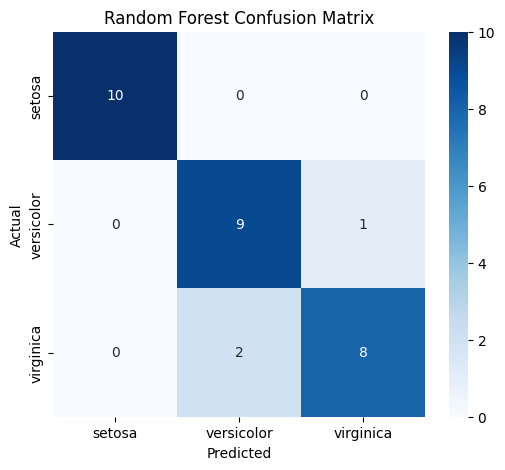


Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names  # Class labels

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train a Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Make predictions
y_pred = rf.predict(X_test)

# Generate Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

# Print Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=target_names))


Decision Tree Accuracy: 0.9333
SVM Accuracy: 0.9667
Logistic Regression Accuracy: 0.9667
Stacking Classifier Accuracy: 0.9667


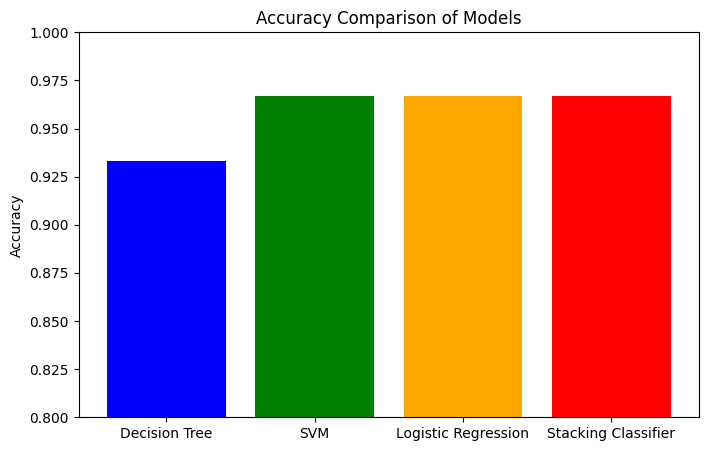

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define base learners
dt = DecisionTreeClassifier(random_state=42)
svm = SVC(probability=True, random_state=42)  # Enable probability for stacking
lr = LogisticRegression(max_iter=200, random_state=42)

# Define Stacking Classifier
stacking_clf = StackingClassifier(
    estimators=[('dt', dt), ('svm', svm), ('lr', lr)],
    final_estimator=LogisticRegression(),
    n_jobs=-1
)

# Train and evaluate models
models = {'Decision Tree': dt, 'SVM': svm, 'Logistic Regression': lr, 'Stacking Classifier': stacking_clf}

accuracies = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

# Plot Accuracy Comparison
plt.figure(figsize=(8, 5))
plt.bar(accuracies.keys(), accuracies.values(), color=['blue', 'green', 'orange', 'red'])
plt.ylabel('Accuracy')
plt.title('Accuracy Comparison of Models')
plt.ylim(0.8, 1.0)
plt.show()


Top 5 Most Important Features:
1. petal width (cm) - Importance: 0.4372
2. petal length (cm) - Importance: 0.4315
3. sepal length (cm) - Importance: 0.1163
4. sepal width (cm) - Importance: 0.0150


<ipython-input-8-cb9c2514870d>:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[sorted_indices], y=np.array(feature_names)[sorted_indices], palette="viridis")


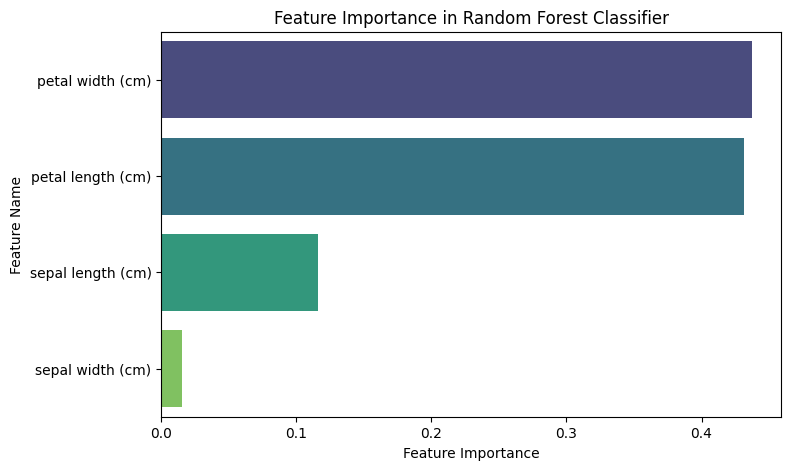

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names  # Feature labels

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train a Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Get feature importances
importances = rf.feature_importances_

# Create a sorted list of feature importances
sorted_indices = np.argsort(importances)[::-1]  # Sort in descending order

# Print top 5 important features
print("Top 5 Most Important Features:")
for i in range(5):
    if i < len(feature_names):  # Ensure we don't exceed available features
        print(f"{i + 1}. {feature_names[sorted_indices[i]]} - Importance: {importances[sorted_indices[i]]:.4f}")

# Plot Feature Importances
plt.figure(figsize=(8, 5))
sns.barplot(x=importances[sorted_indices], y=np.array(feature_names)[sorted_indices], palette="viridis")
plt.xlabel("Feature Importance")
plt.ylabel("Feature Name")
plt.title("Feature Importance in Random Forest Classifier")
plt.show()



Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



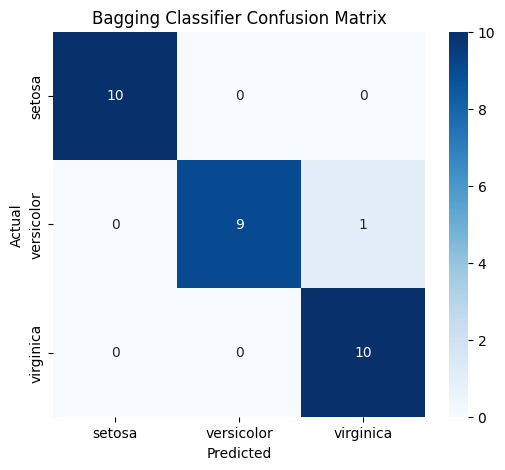

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names  # Class labels

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ✅ Corrected: Use "estimator" instead of "base_estimator"
bagging_clf = BaggingClassifier(estimator=DecisionTreeClassifier(),
                                n_estimators=50, random_state=42, n_jobs=-1)

# Train the model
bagging_clf.fit(X_train, y_train)

# Predict on test data
y_pred = bagging_clf.predict(X_test)

# Evaluate performance
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

# Generate Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Bagging Classifier Confusion Matrix")
plt.show()


Max Depth: 2 | Train Acc: 0.9750 | Test Acc: 0.9000
Max Depth: 4 | Train Acc: 1.0000 | Test Acc: 0.9667
Max Depth: 6 | Train Acc: 1.0000 | Test Acc: 0.9000
Max Depth: 8 | Train Acc: 1.0000 | Test Acc: 0.9000
Max Depth: 10 | Train Acc: 1.0000 | Test Acc: 0.9000
Max Depth: 12 | Train Acc: 1.0000 | Test Acc: 0.9000
Max Depth: None | Train Acc: 1.0000 | Test Acc: 0.9000


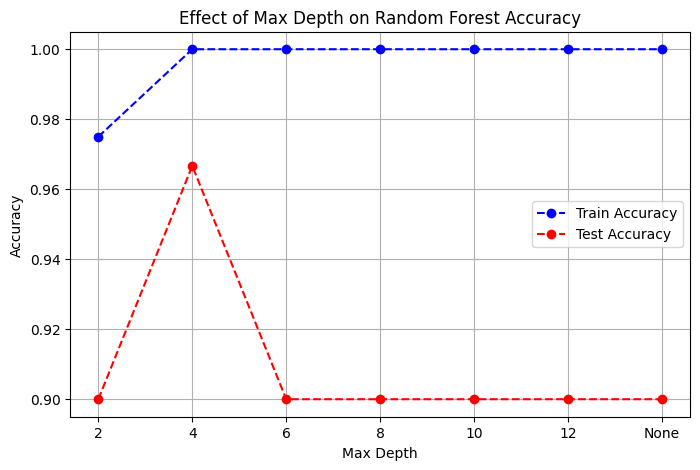

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define different max_depth values to analyze
max_depth_values = [2, 4, 6, 8, 10, 12, None]  # None means no depth limit

# Store accuracy scores
train_accuracies = []
test_accuracies = []

# Train and evaluate models
for max_depth in max_depth_values:
    rf = RandomForestClassifier(n_estimators=100, max_depth=max_depth, random_state=42)
    rf.fit(X_train, y_train)

    # Compute accuracy
    train_acc = accuracy_score(y_train, rf.predict(X_train))
    test_acc = accuracy_score(y_test, rf.predict(X_test))

    # Store results
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"Max Depth: {max_depth} | Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

# Plot Accuracy vs. Max Depth
plt.figure(figsize=(8, 5))
plt.plot([str(md) for md in max_depth_values], train_accuracies, marker='o', linestyle='--', color='b', label='Train Accuracy')
plt.plot([str(md) for md in max_depth_values], test_accuracies, marker='o', linestyle='--', color='r', label='Test Accuracy')
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Max Depth on Random Forest Accuracy")
plt.legend()
plt.grid(True)
plt.show()


Decision Tree | MSE: 0.2573 | R² Score: 0.8036
K-Neighbors | MSE: 1.0763 | R² Score: 0.1787


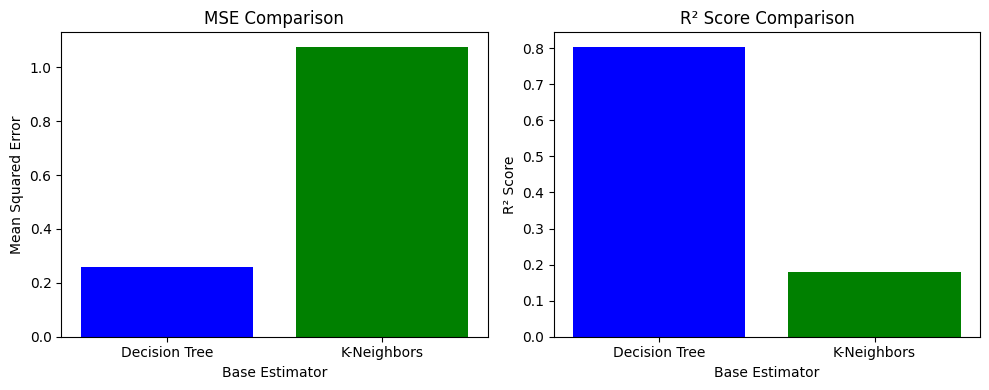

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
housing = fetch_california_housing()
X = housing.data
y = housing.target

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define base estimators
estimators = {
    "Decision Tree": DecisionTreeRegressor(),
    "K-Neighbors": KNeighborsRegressor()
}

# Store results
mse_scores = {}
r2_scores = {}

# Train and evaluate models
for name, estimator in estimators.items():
    bagging_reg = BaggingRegressor(estimator=estimator, n_estimators=50, random_state=42, n_jobs=-1)
    bagging_reg.fit(X_train, y_train)

    # Predict on test data
    y_pred = bagging_reg.predict(X_test)

    # Evaluate performance
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    mse_scores[name] = mse
    r2_scores[name] = r2

    print(f"{name} | MSE: {mse:.4f} | R² Score: {r2:.4f}")

# Plot MSE Comparison
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.bar(mse_scores.keys(), mse_scores.values(), color=['blue', 'green'])
plt.xlabel("Base Estimator")
plt.ylabel("Mean Squared Error")
plt.title("MSE Comparison")

# Plot R² Score Comparison
plt.subplot(1, 2, 2)
plt.bar(r2_scores.keys(), r2_scores.values(), color=['blue', 'green'])
plt.xlabel("Base Estimator")
plt.ylabel("R² Score")
plt.title("R² Score Comparison")

plt.tight_layout()
plt.show()


ROC-AUC Score: 0.9937


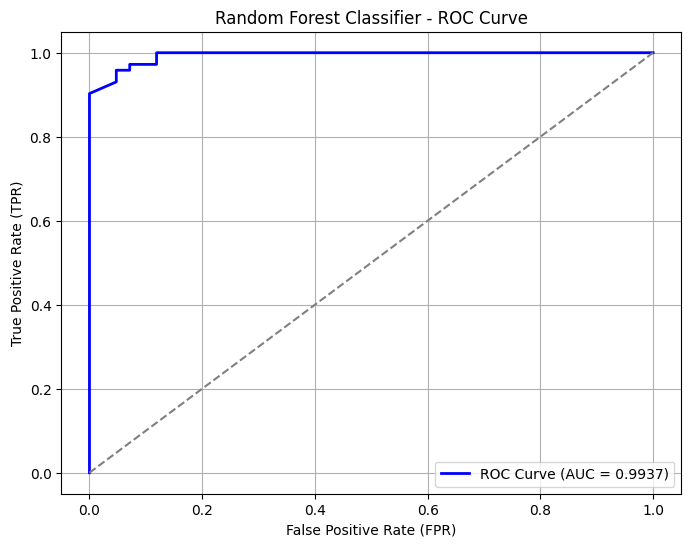

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, auc

# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target  # Binary classification (0 = malignant, 1 = benign)

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train a Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predict probabilities for ROC-AUC (we need probability scores, not class labels)
y_probs = rf.predict_proba(X_test)[:, 1]  # Probability for the positive class

# Compute ROC-AUC Score
roc_auc = roc_auc_score(y_test, y_probs)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Compute ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc_value = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc_value:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line (random model)
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Random Forest Classifier - ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


In [15]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# Load dataset
iris = load_iris()
X, y = iris.data, iris.target

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define Bagging Classifier with Decision Tree as base estimator (Fixed the deprecated argument)
bagging_clf = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=50, random_state=42, n_jobs=-1)

# Perform Cross-Validation (5-fold)
cv_scores = cross_val_score(bagging_clf, X_train, y_train, cv=5, scoring='accuracy')

# Print Cross-Validation Results
print(f"Cross-Validation Scores: {cv_scores}")
print(f"Mean Accuracy: {np.mean(cv_scores):.4f}")

# Train on full training set and evaluate on test set
bagging_clf.fit(X_train, y_train)
test_accuracy = bagging_clf.score(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.4f}")



Cross-Validation Scores: [0.91666667 0.95833333 0.95833333 0.91666667 0.95833333]
Mean Accuracy: 0.9417
Test Accuracy: 0.9667


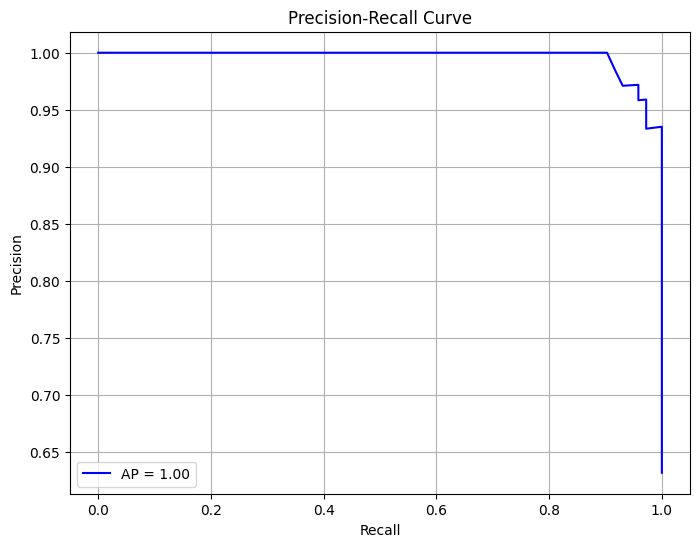

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, average_precision_score

# Load dataset (Binary classification)
data = load_breast_cancer()
X, y = data.data, data.target

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

# Get predicted probabilities for the positive class
y_scores = rf_clf.predict_proba(X_test)[:, 1]

# Compute Precision-Recall values
precision, recall, _ = precision_recall_curve(y_test, y_scores)
avg_precision = average_precision_score(y_test, y_scores)

# Plot Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='b', label=f'AP = {avg_precision:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid()
plt.show()


In [17]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load dataset (Binary classification)
data = load_breast_cancer()
X, y = data.data, data.target

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define Base Models
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# Define Stacking Classifier
stacking_clf = StackingClassifier(
    estimators=[('rf', rf_clf), ('log_reg', log_reg)],
    final_estimator=LogisticRegression(max_iter=1000)
)

# Train and Evaluate Models
models = {'Random Forest': rf_clf, 'Logistic Regression': log_reg, 'Stacking Classifier': stacking_clf}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {accuracy:.4f}")


Random Forest Accuracy: 0.9561


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Accuracy: 0.9561


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Stacking Classifier Accuracy: 0.9561


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Bootstrap Sample Size: 0.2 | MSE: 0.2946 | R² Score: 0.7752
Bootstrap Sample Size: 0.5 | MSE: 0.2664 | R² Score: 0.7967
Bootstrap Sample Size: 0.8 | MSE: 0.2643 | R² Score: 0.7983
Bootstrap Sample Size: 1.0 | MSE: 0.2573 | R² Score: 0.8036


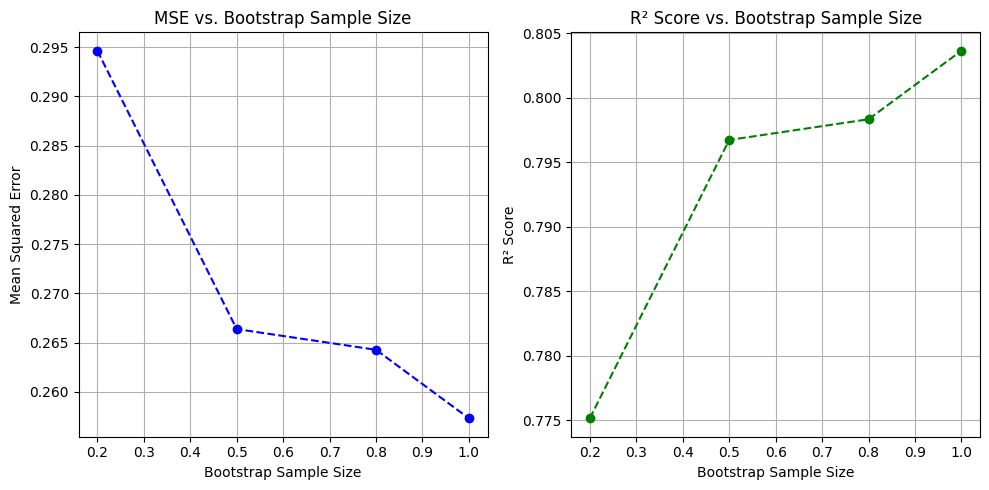

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
data = fetch_california_housing()
X, y = data.data, data.target

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define different bootstrap sample sizes to compare
bootstrap_samples = [0.2, 0.5, 0.8, 1.0]  # Percentage of samples used per base estimator

# Store performance results
mse_scores = []
r2_scores = []

# Train and evaluate models for different bootstrap sample sizes
for sample_size in bootstrap_samples:
    bagging_reg = BaggingRegressor(
        estimator=DecisionTreeRegressor(),  # ✅ Corrected: Use "estimator" instead of "base_estimator"
        n_estimators=50,
        max_samples=sample_size,
        random_state=42,
        n_jobs=-1
    )

    # Train model
    bagging_reg.fit(X_train, y_train)

    # Predict on test set
    y_pred = bagging_reg.predict(X_test)

    # Evaluate performance
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    mse_scores.append(mse)
    r2_scores.append(r2)

    print(f"Bootstrap Sample Size: {sample_size} | MSE: {mse:.4f} | R² Score: {r2:.4f}")

# Plot performance comparison
plt.figure(figsize=(10, 5))

# MSE Plot
plt.subplot(1, 2, 1)
plt.plot(bootstrap_samples, mse_scores, marker='o', linestyle='--', color='b')
plt.xlabel('Bootstrap Sample Size')
plt.ylabel('Mean Squared Error')
plt.title('MSE vs. Bootstrap Sample Size')
plt.grid()

# R² Score Plot
plt.subplot(1, 2, 2)
plt.plot(bootstrap_samples, r2_scores, marker='o', linestyle='--', color='g')
plt.xlabel('Bootstrap Sample Size')
plt.ylabel('R² Score')
plt.title('R² Score vs. Bootstrap Sample Size')
plt.grid()

plt.tight_layout()
plt.show()
